In [10]:
import os
import itertools
import numpy as np
import pandas as pd
import scanpy as sc
import gseapy as gp
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches

import warnings
import scipy.cluster.hierarchy as sch

from anndata import AnnData
from typing import Tuple, Literal
from scipy.stats import pearsonr

In [11]:
for mod in [np, pd, sc, gp]:
    print(mod, mod.__version__)

<module 'numpy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/numpy/__init__.py'> 2.1.0
<module 'pandas' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/pandas/__init__.py'> 2.2.3
<module 'scanpy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/scanpy/__init__.py'> 1.11.1
<module 'gseapy' from '/Users/soeren.becker/micromamba/envs/env_gsea/lib/python3.10/site-packages/gseapy/__init__.py'> 1.1.8


In [12]:
def vprint(msg, verbose):
    if verbose:
        print(msg)

def get_genesets(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype_signature: str,
    direction: str,
    threshold_pval: float,
    threshold_lfc: float, 
) -> Tuple[dict[str, list[str]], pd.DataFrame]:

    # construct signature gene set
    select = ((df_hcd_all.adj_p_value <= threshold_pval) & (df_hcd_all.celltype == celltype_signature))
    if direction == "upregulated":
        select = select & (df_hcd_all.log_fc >= threshold_lfc)
    elif direction == "downregulated":
        select = select & (df_hcd_all.log_fc <= threshold_lfc)
    elif direction == "both":
        select = select & (df_hcd_all.log_fc.abs() >= threshold_lfc)         
    else:
        raise ValueError()
    df_hcd_ct = df_hcd_all.loc[select]
    
    gene_set_dict = {}
    gene_set_df = pd.DataFrame()
    for cytokine_i, cytokine in enumerate(df_hcd_ct.cytokine.unique()):
        gene_set = df_hcd_ct.loc[df_hcd_ct.cytokine == cytokine].gene.values
        gene_set_shared = np.intersect1d(gene_set, adata.var_names)
        gene_set_df.loc[cytokine_i, "cytokine"] = cytokine
        gene_set_df.loc[cytokine_i, "num_genes_signature"] = len(gene_set)
        gene_set_df.loc[cytokine_i, "num_shared_genes_signature"] = len(gene_set_shared)
        gene_set_df.loc[cytokine_i, "frac_shared_genes_signature"] = len(gene_set_shared) / len(gene_set)
        gene_set_dict[cytokine] = gene_set_shared        

    return gene_set_dict, gene_set_df


def compute_mu_and_sigma(adata: AnnData, contrast_column: str, condition: str) -> pd.DataFrame:

    group = adata[adata.obs[contrast_column] == condition]
    num_cells = group.shape[0]
    X = group.X.toarray() if hasattr(group.X, "toarray") else group.X
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0, ddof=1)
    return {"mu": mu, "sigma": sigma, "num_cells": num_cells}


def compute_s2n(
    adata: AnnData, 
    contrast_column: str, 
    condition_1: str, 
    condition_2: str,
    precomputed_stats: dict | None = None
    
) -> (pd.DataFrame, pd.DataFrame):
    """
    Compute the signal-to-noise ratio (S2N) for each gene between two conditions in an AnnData object.

    Parameters:
    - adata: AnnData object with gene expression data.
    - contrast_column: Key in `adata.obs` indicating the condition labels (e.g. "disease_state").
    - condition_1: Name of the first condition (e.g., "flare").
    - condition_2: Name of the second condition (e.g., "healthy").
    
    Returns:
    - s2n_scores: pandas Series of S2N values indexed by gene names.
    """

    if precomputed_stats is None:
    
        # Select cells for each condition
        group1 = adata[adata.obs[contrast_column] == condition_1]
        group2 = adata[adata.obs[contrast_column] == condition_2]
    
        # print("group1.shape", group1.shape)
        # print("group2.shape", group2.shape)
        
        # number of cells per condition
        num_cells_1 = group1.shape[0]
        num_cells_2 = group2.shape[0]
        
        # Get expression matrices
        X1 = group1.X.toarray() if hasattr(group1.X, "toarray") else group1.X
        X2 = group2.X.toarray() if hasattr(group2.X, "toarray") else group2.X
    
        # Compute mean and std per gene
        mu1 = np.mean(X1, axis=0)
        mu2 = np.mean(X2, axis=0)
        sigma1 = np.std(X1, axis=0, ddof=1)
        sigma2 = np.std(X2, axis=0, ddof=1)

    else:
        vprint("Using precomputed stats", True)
        num_cells_1 = precomputed_stats[condition_1]["num_cells"]
        num_cells_2 = precomputed_stats[condition_2]["num_cells"]
        mu1 = precomputed_stats[condition_1]["mu"]
        mu2 = precomputed_stats[condition_2]["mu"]
        sigma1 = precomputed_stats[condition_1]["sigma"]
        sigma2 = precomputed_stats[condition_2]["sigma"]

    # Compute S2N
    s2n = (mu1 - mu2) / (sigma1 + sigma2 + 1e-8)  # epsilon to avoid division by zero

    num_cells = pd.DataFrame(index=[f"{condition_1}_vs_{condition_2}"], columns=["num_cells_1", "num_cells_2"], data=[[num_cells_1, num_cells_2]])
    stats = pd.DataFrame(s2n, index=adata.var_names, columns=[f"{condition_1}_vs_{condition_2}"])
    
    return stats, num_cells

  
def compute_ranking_statistic(adata: AnnData, contrast_column: str, contrasts: list[Tuple[str, str]]) -> (pd.DataFrame, pd.DataFrame):
    rnk_stats, num_cells = [], []
    precomputed_stats = {}

    conditions = []
    for condition in contrasts:
        conditions.extend([condition[0], condition[1]])
    conditions = np.unique(conditions)
    
    for condition in conditions:
        precomputed_stats[condition] = compute_mu_and_sigma(
            adata, 
            contrast_column=contrast_column, 
            condition=condition
        )

    for condition in contrasts:
        _rnk_stats, _num_cells = compute_s2n(
            adata,
            contrast_column=contrast_column,
            condition_1=condition[0],
            condition_2=condition[1],
            precomputed_stats=precomputed_stats,
        )
        rnk_stats.append(_rnk_stats)
        num_cells.append(_num_cells)
    return pd.concat(rnk_stats, axis=1), pd.concat(num_cells, axis=0)

    
def run_enrichment_test(
    adata: AnnData,
    df_hcd_all: pd.DataFrame,
    celltype: Tuple[str, str] = ("B cell", "B"),
    direction: str = "upregulated",
    threshold_pval: float = 0.01,
    threshold_lfc: float = 1.,
    threshold_expression: float = 0,
    contrast_column: str = "disease_state",
    celltype_column: str = "disease_state",
    contrasts: Tuple[str, str] | list[Tuple[str, str]] = None,
    min_size: int = 10,
    max_size: int = 1000,
    permutation_num: int = 1000,
    weight: float = 1.,
    max_obs_per_condition: int | None = None, # None = all
    seed: int = 2025,
    verbose: bool = True,
    threads: int = 6,
    min_num_cells: int = 20,
) -> pd.DataFrame:

    if not isinstance(contrasts, list):
        assert isinstance(contrasts, Tuple)
        contrasts = [contrasts]
        
    celltype_adata = celltype[0]
    celltype_signature = celltype[1]
    
    # filter for cell type
    vprint("Filter for cell type:", verbose)
    adata = adata[adata.obs[celltype_column] == celltype_adata]
    if adata.shape[0] < min_num_cells:
        print(f"To few cells: {adata.shape[0]}")
        return None

    contrast_value_counts = adata.obs.loc[:, "disease_state"].value_counts()
    print(contrast_value_counts)
    valid_contrast_values = contrast_value_counts.index[contrast_value_counts >= min_num_cells].values
    print(valid_contrast_values)
    adata = adata[(adata.obs.loc[:, contrast_column].isin(valid_contrast_values))]
    remaining_contrasts = []
    for contrast in contrasts:
        if not contrast[0] in valid_contrast_values:
            print(f"Removing contrast: {contrast}")
            continue
        if not contrast[1] in valid_contrast_values:
            print(f"Removing contrast: {contrast}")
            continue
        remaining_contrasts.append(contrast)
    print(f"Updated contrasts are: {remaining_contrasts}")
    contrasts = remaining_contrasts
    if len(contrasts) == 0:
        return None
        
    vprint("Filter for cell type: done.", verbose)
    
    # filter based on gene expression
    vprint("Filter for gene expression:", verbose)
    adata = adata[:, adata.X.mean(axis=0) >= threshold_expression]
    vprint("Filter for gene expression: done.", verbose)

    # get genesets
    vprint("Get gene sets:", verbose)
    gene_set_dict, gene_set_df = get_genesets(
        adata=adata,
        df_hcd_all=df_hcd_all,
        celltype_signature=celltype_signature,
        direction=direction,
        threshold_pval=threshold_pval,
        threshold_lfc=threshold_lfc,
    )
    vprint("Get gene sets: done.", verbose)
    
    # compute ranking stat
    vprint("Get ranking stats:", verbose)
    rnk_stats, num_cells_per_condition = compute_ranking_statistic(adata, contrast_column=contrast_column, contrasts=contrasts)
    vprint("Get ranking stats: done.", verbose)
    results = []
    
    for contrast_name in rnk_stats.columns:
        print(contrast_name)
        # format stat so that it can be processed be gseapy
        rnk = rnk_stats.loc[:, contrast_name]\
            .replace([np.inf, -np.inf], np.nan)\
            .dropna()\
            .sort_values(ascending=False)\
            .to_frame()\
            .rename({contrast_name: 1}, axis=1)\
            .rename_axis("0")
        
        # run enrichment
        gp_res = gp.prerank(
            rnk=rnk,
            gene_sets=gene_set_dict,
            min_size=min_size,
            max_size=max_size,
            permutation_num=permutation_num,
            weight=weight,
            outdir=None,
            seed=seed,
            verbose=verbose,
            threads=threads,
        )
        _res = gp_res.res2d
        _res.loc[:, "contrast"] = contrast_name
        _res.loc[:, "num_cells_1"] = num_cells_per_condition.loc[contrast_name, "num_cells_1"]
        _res.loc[:, "num_cells_2"] = num_cells_per_condition.loc[contrast_name, "num_cells_2"]
        _res.loc[:, "percent_duplicate_ranking_stats"] = (rnk.duplicated(keep="first").sum() / rnk.shape[0]) * 100
        results.append(_res)
        vprint(f"{contrast_name}: done.", verbose)

    # combine results and save hyperparams
    results = pd.concat(results, axis=0, ignore_index=True)
    results.loc[:, "celltype_adata"] = celltype_adata
    results.loc[:, "celltype_signature"] = celltype_signature
    results.loc[:, "celltype_combo"] = f"{celltype_adata} ({celltype_signature})"
    results.loc[:, "direction"] = direction
    results.loc[:, "threshold_pval"] = threshold_pval
    results.loc[:, "threshold_lfc"] = threshold_lfc
    results.loc[:, "threshold_expression"] = threshold_expression
    results.loc[:, "min_size"] = min_size
    results.loc[:, "max_size"] = max_size
    results.loc[:, "permutation_num"] = permutation_num
    results.loc[:, "weight"] = weight
    results.loc[:, "seed"] = seed
    results.loc[:, "threads"] = threads

    results.rename({"Term": "cytokine"}, inplace=True, axis=1)
    results = pd.merge(results, gene_set_df, on="cytokine")
    
    return results

In [ ]:
df_hcd_all = pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/data/DEGs/DEGs_all_with_pbs_DE_count.csv", index_col=0)
questionable_genes = set(pd.read_csv("/Users/soeren.becker/repos/HumanCytokineDict/notebooks/01_overview/questionable_genes.csv")['gene'])
df_hcd_all = df_hcd_all.loc[
    (
        (df_hcd_all['pbs_well'] > 3) 
        & (~df_hcd_all['gene'].isin(questionable_genes))
        & (df_hcd_all['adj_p_value'] < 0.05)
    )
]

In [ ]:
hcd_celltypes = df_hcd_all.celltype.unique()
hcd_celltypes

In [14]:
adata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/06_lupus/lupus_norm_log1p.h5ad")

In [ ]:
if False:
    df_mart_conversion = pd.read_csv("/Users/soeren.becker/Downloads/mart_export (1).txt", skiprows=0, sep="\t")
    df_mart_conversion.columns = [c.strip().lower().replace(" ", "_") for c in df_mart_conversion.columns]
    id_to_symbol = dict(zip(df_mart_conversion['gene_stable_id'], df_mart_conversion['hgnc_symbol']))
    adata.var['gene_symbol'] = adata.var_names.map(id_to_symbol)

In [ ]:
ensembl_to_symbol = pd.read_pickle("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/06_lupus/ens_id_to_symbol.pkl")
adata.var['gene_symbol'] = adata.var_names.map(ensembl_to_symbol)
adata.var.loc[:, "new_index"] = adata.var.gene_symbol
adata.var.loc[adata.var.new_index.isna(), "new_index"] = adata.var.loc[adata.var.new_index.isna()].index
adata.var = adata.var.reset_index().set_index("new_index")
display(adata.var)

display(adata.var_names.value_counts())

adata.var_names_make_unique()

In [ ]:
celltype_combos = (
    ("B cell", "B_cell"),
    ('CD4-positive, alpha-beta T cell', "CD4_T_cell"),
    ('CD8-positive, alpha-beta T cell', "CD8_T_cell"),
    ('classical monocyte', "CD14_Mono"),
    ('non-classical monocyte', "CD16_Mono"),
    ('natural killer cell', "NK_CD56hi"),
    ('natural killer cell', "NK_CD56low"),
    ('conventional dendritic cell', "cDC"),
)

for combo in celltype_combos:
    assert combo[1] in hcd_celltypes

In [ ]:
contrasts = [("flare", "treated")]

In [ ]:
treated_donor_ids = adata.obs.loc[adata.obs.disease_state == "treated"].donor_id.unique()
treated_donor_ids

In [ ]:
adata.shape

In [ ]:
adata = adata[adata.obs.donor_id.isin(treated_donor_ids)]

In [ ]:
adata.obs.cell_type.value_counts()

In [ ]:
result_dir = "./results_robustness_final_DEGs_matched_treated_vs_flare"
os.makedirs(result_dir, exist_ok=True)

### all paired donors together

In [ ]:
if False:
    threshold_pval = 0.05
    
    all_results = []
    
    for celltype_combo_k, celltype_combo in enumerate(celltype_combos):
        
        shared_kwargs = {
            "threshold_pval": threshold_pval,
            "direction": "upregulated",
            "min_size": 8,
            "max_size": 1_000,
            "permutation_num": 20_000,
            "verbose": True,
            "df_hcd_all": df_hcd_all,
            "adata": adata,
        }
    
        # for threshold_lfc in [0.8, 0.9, 1, 1.1, 1.2,]:
        for threshold_lfc in [1]:
            shared_kwargs["threshold_lfc"] = threshold_lfc
            # for threshold_expression in [0, 0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]:
            # for threshold_expression in [0.01, 0.02, 0.03, 0.04]:
            # for threshold_expression in [0.05, 0.06, 0.07, 0.08, 0.09, 0.1]:
            for threshold_expression in [0.05]:
    
                print(celltype_combo, threshold_lfc, threshold_expression)
                
                shared_kwargs["threshold_expression"] = threshold_expression
                results = run_enrichment_test(
                    celltype=celltype_combo,
                    contrast_column="disease_state",
                    celltype_column="cell_type",
                    contrasts=contrasts,
                    **shared_kwargs,
                )
                if results is not None:
                    all_results.append(results)
    
    all_results = pd.concat(all_results, axis=0)
    all_results.to_csv(os.path.join(result_dir, "./results_lupus_matched_flare_vs_treated.csv"))

In [ ]:
contrasts

In [ ]:
threshold_pval = 0.05
all_results = []

thresholds_expression = [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.08, 0.09, 0.1]

celltype_combos = (
    ("B cell", "B_cell"),
    ('CD4-positive, alpha-beta T cell', "CD4_T_cell"),
    ('CD8-positive, alpha-beta T cell', "CD8_T_cell"),
    ('classical monocyte', "CD14_Mono"),
    ('non-classical monocyte', "CD16_Mono"),
    ('natural killer cell', "NK_CD56hi"),
    ('natural killer cell', "NK_CD56low"),
    ('conventional dendritic cell', "cDC"),
)


for donor_id in ['FLARE004', 'FLARE013', '1586', 'FLARE011']: #adata.obs.donor_id.unique():

    shared_kwargs = {
        "threshold_pval": threshold_pval,
        "direction": "upregulated",
        "min_size": 8,
        "max_size": 1_000,
        "permutation_num": 20_000,
        "verbose": True,
        "df_hcd_all": df_hcd_all,
        "adata": adata[adata.obs.donor_id == donor_id],
        "min_num_cells": 50,
        
    }
    
    for celltype_combo_k, celltype_combo in enumerate(celltype_combos):
        
        for threshold_lfc in [0.8, 0.9, 1, 1.1, 1.2]:
            shared_kwargs["threshold_lfc"] = threshold_lfc
            
            for threshold_expression in thresholds_expression:
                shared_kwargs["threshold_expression"] = threshold_expression

                print(donor_id, celltype_combo, threshold_lfc, threshold_expression)
                
                results = run_enrichment_test(
                    celltype=celltype_combo,
                    contrast_column="disease_state",
                    celltype_column="cell_type",
                    contrasts=contrasts,
                    **shared_kwargs,
                )
                if results is not None:
                    results.loc[:, "donor_id"] = donor_id
                    all_results.append(results)

all_results = pd.concat(all_results, axis=0)
all_results.to_csv(
    os.path.join(
        result_dir, 
        f"./results_lupus_matched_flare_vs_treated_per_donor_lfc_{thresholds_expression}_{donor_id}___saturday_night.csv"
    )
)



In [17]:
from tqdm.auto import tqdm
import warnings

def _check_robustness_fractions(
    df_pivot, 
    threshold_qval=0.1, # adjusted p value
    threshold_valid=0.8, # fraction of results required to even consider this condition. I.e. if the test only ran for one set of thresholds, then it is not very robust.
    threshold_below_alpha=0.75, # fraction of results that need to be significant
):
    n_total = np.prod(df_pivot.shape)
    n_valid = n_total - df_pivot.isna().sum().sum()
    n_below_alpha = (df_pivot < threshold_qval).sum().sum() # number of results below pval threshold, i.e., number of significant results
    frac_valid_results = (n_valid / n_total)
    frac_pval_below_alpha = (n_below_alpha / n_valid) # fraction of significant results relative to valid results
    is_robust = (frac_pval_below_alpha > threshold_below_alpha) & (frac_valid_results > threshold_valid)
    return frac_valid_results, frac_pval_below_alpha, is_robust

def check_robustness(
    all_results,
    THRESHOLD_QVAL = 0.1,
    THRESHOLD_VALID = 0.5,
    THRESHOLD_BELOW_ALPHA = 0.9,
):
    
    all_thresholds_expression = all_results.threshold_expression.sort_values(ascending = False).unique()
    all_thresholds_lfc = sorted(all_results.threshold_lfc.unique())
    
    df = pd.DataFrame(index=all_thresholds_expression, columns=all_thresholds_lfc)
    df.index.rename("threshold_expression", inplace=True)
    df.columns.rename("threshold_lfc", inplace=True)

    df2 = df.copy()
    
    robust_results = []
    
    for contrast in tqdm(all_results.contrast.unique()):
        for celltype_combo in all_results.celltype_combo.unique():
            results_ct = all_results.loc[(all_results.celltype_combo == celltype_combo) & (all_results.contrast == contrast)]
            for cytokine in results_ct.cytokine.unique():
                results_ct_cy = results_ct.loc[results_ct.cytokine == cytokine]
                df_pivot = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
                df_pivot_nes = results_ct_cy.pivot(index="threshold_expression", columns="threshold_lfc", values="NES")
                row_order = df_pivot.index.sort_values(ascending=False)
                with warnings.catch_warnings():
                    warnings.simplefilter(action='ignore', category=FutureWarning)
                    df_combined = pd.concat([df, df_pivot])
                    df_combined2 = pd.concat([df2, df_pivot_nes])
                df_merged = df_combined.combine_first(df_pivot)
                df_merged2 = df_combined2.combine_first(df_pivot_nes)
                df_merged = df_merged.loc[~df_merged.index.duplicated()]
                df_merged2 = df_merged2.loc[~df_merged2.index.duplicated()]
                df_pivot = df_merged.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                df_pivot_nes = df_merged2.loc[all_thresholds_expression, all_thresholds_lfc].astype(float)
                frac_valid_results, frac_pval_below_alpha, is_robust = _check_robustness_fractions(
                    df_pivot,
                    threshold_qval=THRESHOLD_QVAL,
                    threshold_valid=THRESHOLD_VALID,
                    threshold_below_alpha=THRESHOLD_BELOW_ALPHA
                )
                
                if is_robust:
                    if (df_pivot_nes.max().max() > 0) and (df_pivot_nes.min().min() < 0):
                        sns.heatmap(df_pivot, cmap="Reds_r", center=0, vmin=0, vmax=0.1, square=True)
                        plt.show()
                        sns.heatmap(df_pivot_nes, cmap="RdBu_r", center=0, square=True)
                        plt.show()
                    robust_results.append(
                        (
                            celltype_combo, contrast, cytokine,
                            frac_valid_results, frac_pval_below_alpha, is_robust,
                            results_ct_cy.NES.min(), results_ct_cy.NES.max(),
                            THRESHOLD_QVAL,
                            THRESHOLD_BELOW_ALPHA,
                        )
                    )
        
    robust_results = pd.DataFrame(robust_results).rename(
        {0: "celltype_combo", 1: "contrast", 2: "cytokine", 3: "frac_valid", 4: "frac_significant", 5:"is_robust", 6:"NES_min", 7:"NES_max", 8:"qval_threshold", 9: "threshold_frac_below_alpha"},
        axis=1
    )
    return robust_results

def format_cytokine_names(x):
    if isinstance(x, (list, np.ndarray, pd.Index)):
        return [format_cytokine_names(_x) for _x in x]
    x = x.get_text() if hasattr(x, 'get_text') else x
    x = x.replace("alpha", r"$\alpha$")
    x = x.replace("beta", r"$\beta$")
    x = x.replace("gamma", r"$\gamma$")
    x = x.replace("omega", r"$\omega$")
    x = x.replace("lambda", r"$\lambda$")
    return x

def format_ethnicity_str(x):
    if x == "Hispanic or Latin American":
        return "Hispanic"
    elif x == "African American":
        return "African Am."
    return x

In [25]:
all_results = pd.read_csv("./results_robustness_final_DEGs_matched_treated_vs_flare/results_lupus_matched_flare_vs_treated_per_donor_complete.csv", index_col=0)
print(all_results.donor_id.unique())
all_results = all_results.loc[(all_results.threshold_expression >= 0.05) & (all_results.threshold_lfc.isin([0.8, 0.9, 1, 1.1, 1.2]))]

['FLARE004' 'FLARE013' '1586' 'FLARE011' '1130' '1763' 'FLARE016'
 'FLARE010' 'FLARE001' 'FLARE009']


  0%|                                                     | 0/1 [00:00<?, ?it/s]

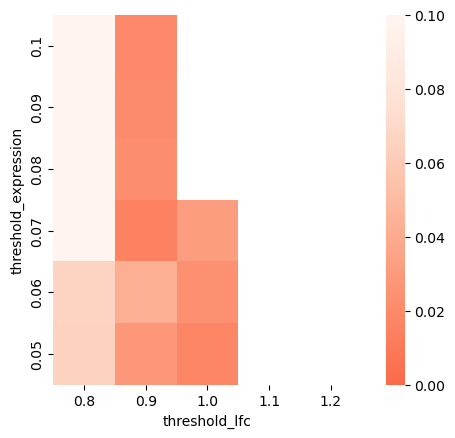

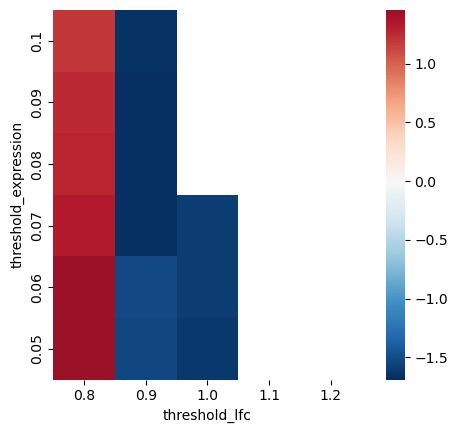

  0%|                                                     | 0/1 [00:00<?, ?it/s]

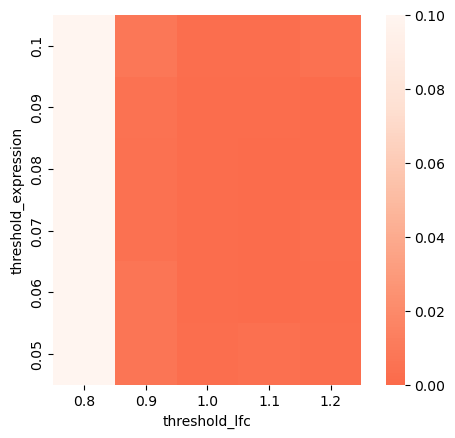

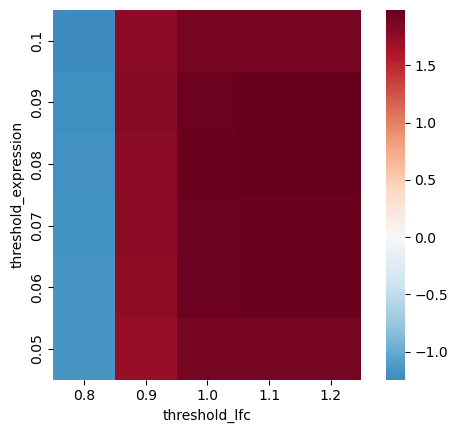

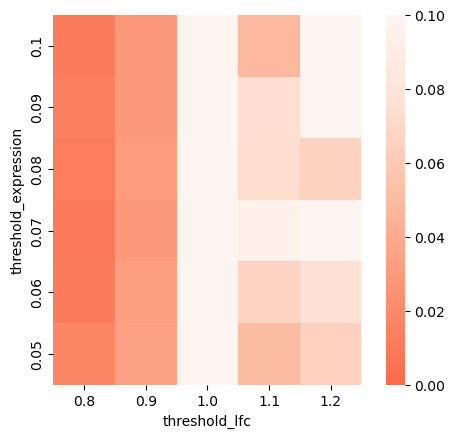

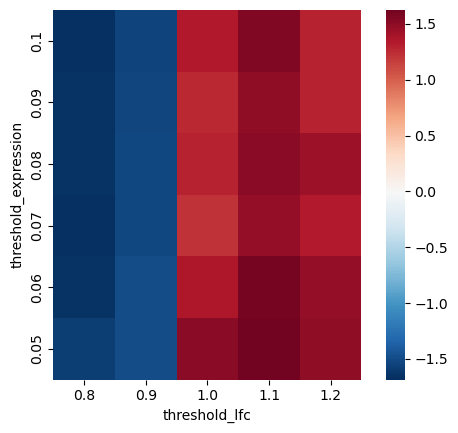

  0%|                                                     | 0/1 [00:00<?, ?it/s]

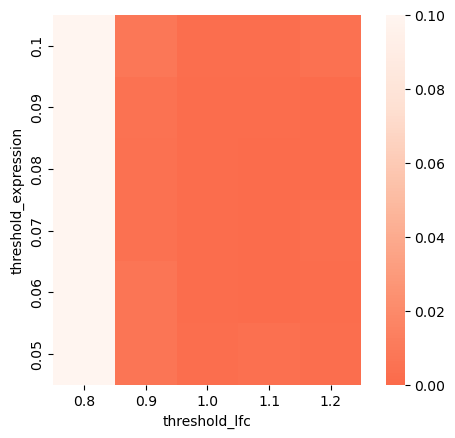

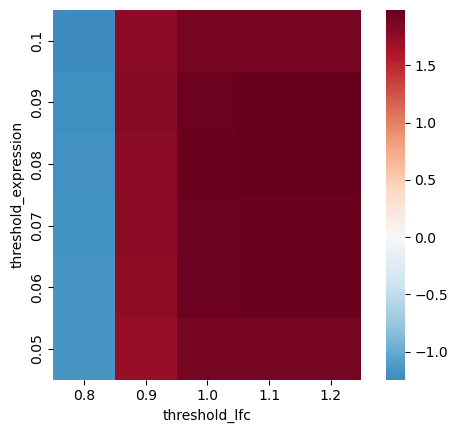

  0%|                                                     | 0/1 [00:00<?, ?it/s]

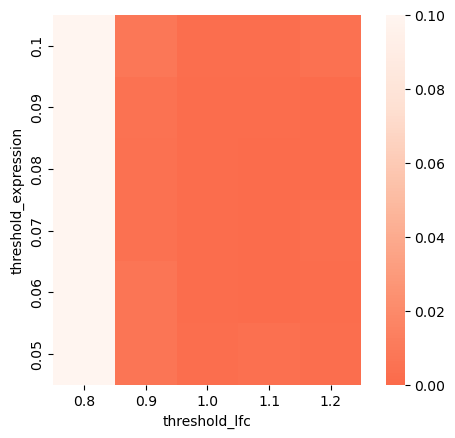

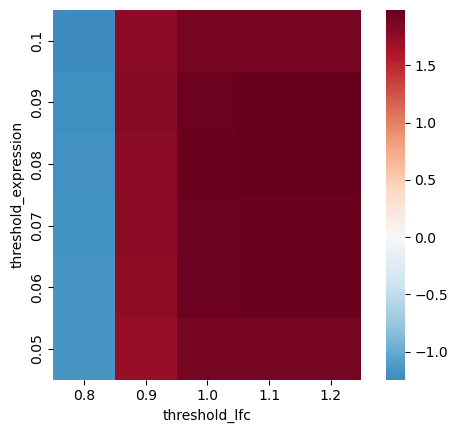

  0%|                                                     | 0/1 [00:00<?, ?it/s]

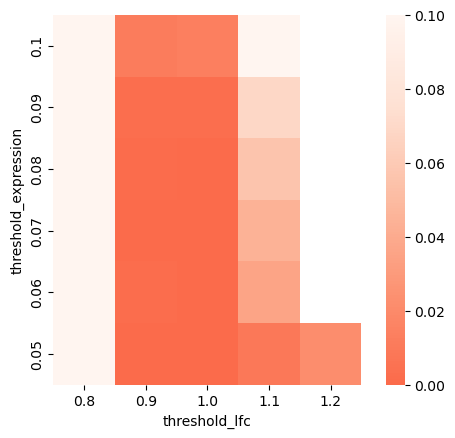

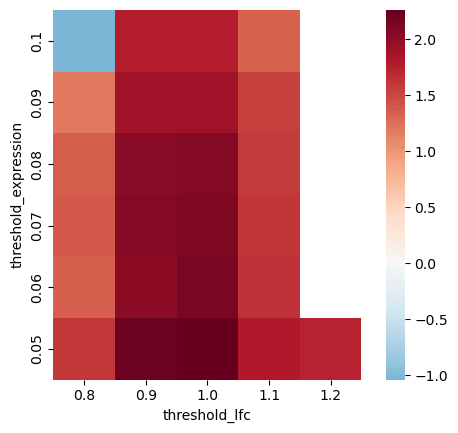

  0%|                                                     | 0/1 [00:00<?, ?it/s]

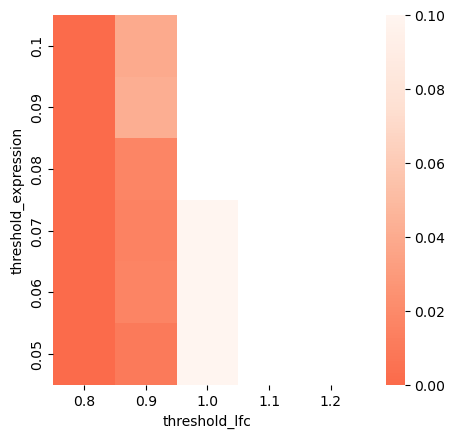

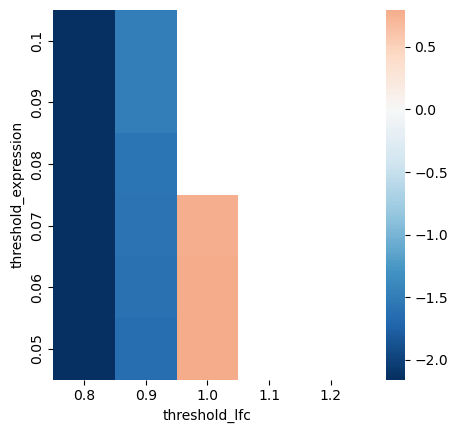

  0%|                                                     | 0/1 [00:00<?, ?it/s]

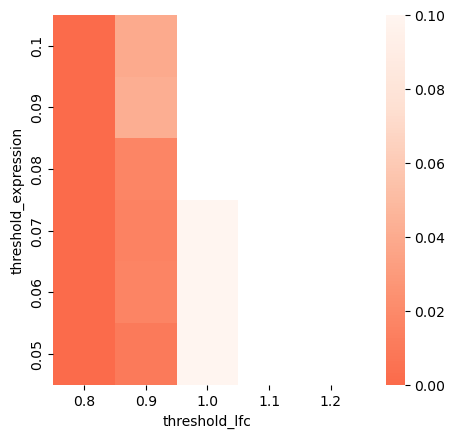

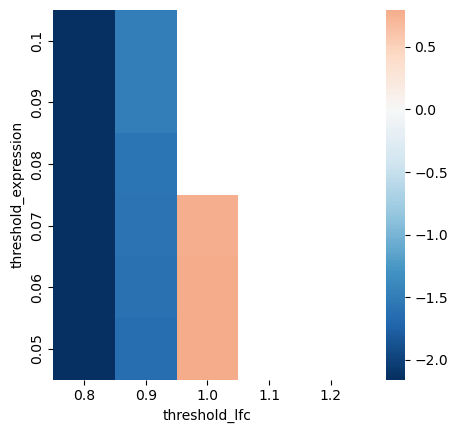

100%|█████████████████████████████████████████████| 1/1 [00:00<00:00,  2.92it/s]


In [26]:
robust_results = []

THRESHOLD_VALID = 1/3
THRESHOLD_BELOW_ALPHA = 2/3

for donor_id in all_results.donor_id.unique():
    for q in [0.1, 0.05, 0.01]:
        _robust_results = check_robustness(all_results.loc[all_results.donor_id == donor_id], THRESHOLD_QVAL=q, THRESHOLD_VALID=THRESHOLD_VALID, THRESHOLD_BELOW_ALPHA=THRESHOLD_BELOW_ALPHA)
        if _robust_results.shape[0] > 0:
            _robust_results.loc[:, "donor_id"] = donor_id
            robust_results.append(_robust_results)

robust_results = pd.concat(robust_results)
robust_results = robust_results.groupby(["celltype_combo", "contrast", "cytokine", "donor_id"])["qval_threshold"].min().to_frame().reset_index()

flare_vs_treated B cell (B_cell) IL-1-beta FLARE009 12 3 0.0 0.7732322997536144
flare_vs_treated classical monocyte (CD14_Mono) IL-1-alpha FLARE004 9 6 0.0153434332969718 0.065488619506987


,Name,cytokine,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,...,max_size,permutation_num,weight,seed,threads,num_genes_signature,num_shared_genes_signature,frac_shared_genes_signature,donor_id,Unnamed: 0
13,prerank,IL-1-alpha,0.539528,1.455993,0.075350,0.065489,0.327300,8/23,7.57%,IFI27;APOBEC3A;IFITM1;TNFSF10;FCGR1A;MT2A;VAMP...,...,1000,20000,1.0,2025,6,156.0,23.0,0.147436,FLARE004,NaN
14,prerank,IL-1-alpha,0.541358,1.442675,0.084137,0.066726,0.363650,8/22,8.72%,IFI27;APOBEC3A;IFITM1;TNFSF10;FCGR1A;MT2A;VAMP...,...,1000,20000,1.0,2025,6,156.0,22.0,0.141026,FLARE004,NaN
16,prerank,IL-1-alpha,0.510756,1.337150,0.133430,0.105135,0.507800,7/21,9.80%,IFI27;APOBEC3A;TNFSF10;FCGR1A;MT2A;VAMP5;GBP2,...,1000,20000,1.0,2025,6,156.0,21.0,0.134615,FLARE004,NaN
15,prerank,IL-1-alpha,0.494335,1.275795,0.180450,0.146301,0.605750,4/19,5.65%,IFI27;APOBEC3A;TNFSF10;FCGR1A,...,1000,20000,1.0,2025,6,156.0,19.0,0.121795,FLARE004,NaN
15,prerank,IL-1-alpha,0.495076,1.253587,0.199459,0.164749,0.647200,4/17,6.23%,IFI27;APOBEC3A;TNFSF10;FCGR1A,...,1000,20000,1.0,2025,6,156.0,17.0,0.108974,FLARE004,NaN
16,prerank,IL-1-alpha,0.482783,1.191888,0.249836,0.223122,0.751350,3/15,6.31%,IFI27;APOBEC3A;TNFSF10,...,1000,20000,1.0,2025,6,156.0,15.0,0.096154,FLARE004,NaN
12,prerank,IL-1-alpha,-0.631566,-1.534088,0.040965,0.028797,0.144685,4/13,3.94%,DUSP1;CXCL8;GLUL;PPBP,...,1000,20000,1.0,2025,6,119.0,13.0,0.109244,FLARE004,NaN
11,prerank,IL-1-alpha,-0.625365,-1.523866,0.046412,0.042226,0.171665,4/13,4.58%,DUSP1;CXCL8;GLUL;PPBP,...,1000,20000,1.0,2025,6,119.0,13.0,0.109244,FLARE004,NaN
7,prerank,IL-1-alpha,-0.705570,-1.689070,0.011830,0.015343,0.047889,4/12,5.13%,DUSP1;CXCL8;GLUL;PPBP,...,1000,20000,1.0,2025,6,119.0,12.0,0.100840,FLARE004,NaN
7,prerank,IL-1-alpha,-0.705209,-1.668166,0.012579,0.021519,0.063525,4/11,5.65%,DUSP1;CXCL8;GLUL;PPBP,...,1000,20000,1.0,2025,6,119.0,11.0,0.092437,FLARE004,NaN


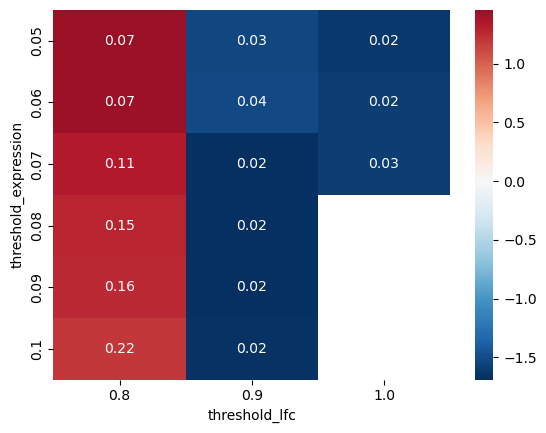

flare_vs_treated classical monocyte (CD14_Mono) M-CSF FLARE013 6 24 0.1648720053892467 0.0010876732629518
flare_vs_treated natural killer cell (NK_CD56low) IL-32-beta 1130 1 24 0.5556926431272117 3.4011870142679796e-05
flare_vs_treated non-classical monocyte (CD16_Mono) IL-1-beta FLARE013 12 18 0.0096820995237928 0.0489569820616638


,Name,cytokine,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes,...,max_size,permutation_num,weight,seed,threads,num_genes_signature,num_shared_genes_signature,frac_shared_genes_signature,donor_id,Unnamed: 0
7,prerank,IL-1-beta,-0.392255,-1.589817,0.005740,0.017969,0.129943,22/81,13.08%,IFITM1;APOBEC3A;GBP1;UBE2L6;CDKN1C;CTSZ;HES4;R...,...,1000,20000,1.0,2025,6,242.0,81.0,0.334711,FLARE013,NaN
7,prerank,IL-1-beta,-0.421608,-1.649233,0.003919,0.011702,0.089926,21/72,14.00%,IFITM1;APOBEC3A;GBP1;UBE2L6;CDKN1C;CTSZ;HES4;R...,...,1000,20000,1.0,2025,6,242.0,72.0,0.297521,FLARE013,NaN
7,prerank,IL-1-beta,-0.437347,-1.685357,0.004405,0.009682,0.074130,21/68,14.35%,IFITM1;APOBEC3A;GBP1;UBE2L6;CDKN1C;CTSZ;HES4;R...,...,1000,20000,1.0,2025,6,242.0,68.0,0.280992,FLARE013,NaN
7,prerank,IL-1-beta,-0.436144,-1.658580,0.005697,0.012420,0.092429,17/66,11.05%,IFITM1;APOBEC3A;GBP1;UBE2L6;CDKN1C;CTSZ;HES4;R...,...,1000,20000,1.0,2025,6,242.0,66.0,0.272727,FLARE013,NaN
7,prerank,IL-1-beta,-0.441271,-1.657089,0.004300,0.012985,0.098794,17/64,11.76%,IFITM1;APOBEC3A;GBP1;UBE2L6;CDKN1C;CTSZ;HES4;R...,...,1000,20000,1.0,2025,6,242.0,64.0,0.264463,FLARE013,NaN
7,prerank,IL-1-beta,-0.459923,-1.674576,0.006219,0.010956,0.079782,17/55,12.41%,IFITM1;APOBEC3A;GBP1;UBE2L6;CDKN1C;CTSZ;HES4;R...,...,1000,20000,1.0,2025,6,242.0,55.0,0.227273,FLARE013,NaN
6,prerank,IL-1-beta,-0.403997,-1.495810,0.029896,0.034137,0.173771,14/51,13.08%,IFITM1;APOBEC3A;GBP1;CDKN1C;CTSZ;HES4;LAMP1;IS...,...,1000,20000,1.0,2025,6,171.0,51.0,0.298246,FLARE013,NaN
7,prerank,IL-1-beta,-0.420164,-1.498342,0.031234,0.032803,0.163135,13/46,14.00%,IFITM1;APOBEC3A;GBP1;CDKN1C;CTSZ;HES4;LAMP1;IS...,...,1000,20000,1.0,2025,6,171.0,46.0,0.269006,FLARE013,NaN
6,prerank,IL-1-beta,-0.431792,-1.522439,0.028123,0.029271,0.146762,13/44,14.35%,IFITM1;APOBEC3A;GBP1;CDKN1C;CTSZ;HES4;LAMP1;IS...,...,1000,20000,1.0,2025,6,171.0,44.0,0.257310,FLARE013,NaN
7,prerank,IL-1-beta,-0.439001,-1.524092,0.025676,0.031015,0.149390,7/42,3.67%,IFITM1;APOBEC3A;GBP1;CDKN1C;CTSZ;HES4;LAMP1,...,1000,20000,1.0,2025,6,171.0,42.0,0.245614,FLARE013,NaN


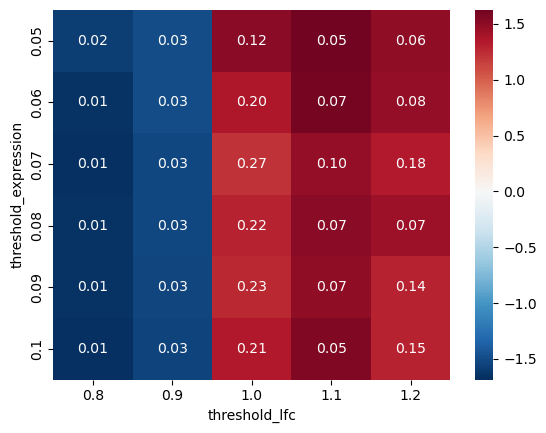

In [27]:
ambivalent_idcs = []

for idx in robust_results.set_index(["contrast", "celltype_combo", "donor_id", "cytokine"]).index:

    contrast, celltype, donor_id, cytokine = idx
    
    _all_results = all_results.loc[
        (
            (all_results.contrast == contrast)
            &(all_results.celltype_combo == celltype)
            &(all_results.donor_id == donor_id)
            &(all_results.cytokine == cytokine)
        )
    ]
    
    m = np.sum(_all_results.NES > 0)
    n = np.sum(_all_results.NES < 0)
    if n > 0 and m > 0:

        q1 = _all_results.loc[_all_results.NES < 0, "FDR q-val"].min()
        q2 = _all_results.loc[_all_results.NES > 0, "FDR q-val"].min()

        ambivalent_idcs.append(idx)
        
        print(contrast, celltype, cytokine, donor_id, n, m, q1, q2)
        if q1 < 0.1 and q2 < 0.1:
            display(_all_results)
            p1 = _all_results.pivot(index="threshold_expression", columns="threshold_lfc", values="NES")
            p2 = _all_results.pivot(index="threshold_expression", columns="threshold_lfc", values="FDR q-val")
            sns.heatmap(p1, annot=p2, fmt=".2f", cmap="RdBu_r", center=0)
            plt.show()
        # assert False

In [28]:
robust_results = robust_results.loc[~robust_results.set_index(["contrast", "celltype_combo", "donor_id", "cytokine"]).index.isin(ambivalent_idcs)]

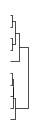

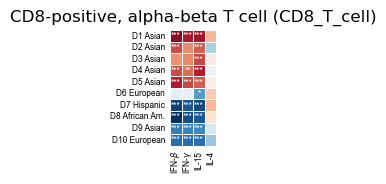

In [59]:
celltype_combo = 'CD8-positive, alpha-beta T cell (CD8_T_cell)'

CYTOKINES = ["IFN-beta", "IFN-gamma", "IL-15", "IL-4"]

df_nes = all_results.loc[(all_results.celltype_combo == celltype_combo)].groupby(["donor_id", "cytokine"])["NES"].mean().to_frame().reset_index()
df_pivot = df_nes.pivot(
    index = "cytokine",
    columns = "donor_id",
    values = "NES"
).astype(float)
df_pivot = df_pivot.loc[CYTOKINES].T
df_annot = df_pivot.copy()


with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    df_annot[:] = ""
for donor_id in df_pivot.index:
    for cytokine in df_pivot.columns:
        qval = robust_results.loc[(robust_results.celltype_combo == celltype_combo) & (robust_results.cytokine == cytokine) & (robust_results.donor_id == donor_id)].qval_threshold
        if len(qval) != 0:
            qval = qval.values[0]
            if qval == 0.1:
                df_annot.loc[donor_id, cytokine] = "*"
            if qval == 0.05:
                df_annot.loc[donor_id, cytokine] = "**"
            if qval == 0.01:
                df_annot.loc[donor_id, cytokine] = "***"


linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='euclidean')
# linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='correlation')
dendro_col = sch.dendrogram(linkage_col, no_plot=True)
col_order = dendro_col['leaves']

fig, ax = plt.subplots(1, 1, figsize=(0.25, 1.5))
sch.dendrogram(linkage_col, ax=ax, color_threshold=0, no_labels=True, link_color_func=lambda _: "black", orientation="right")
ax.axis('off')
ax.collections[0].set_linewidth(0.5)
plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}_dendogram.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.show()


df_reordered = df_pivot.iloc[col_order]
annot_reordered = df_annot.iloc[col_order]

donor_idcs = dict(zip(df_reordered.index, range(1, 1 + len(df_reordered.index))))

def get_ethnicity_label(x):
    assert len(x) == 1
    return x[0]

donor2label = {}
donor2label_ethnicity = dict(adata.obs.loc[adata.obs.donor_id.isin(df_pivot.index)].groupby("donor_id", observed=True)["self_reported_ethnicity"].unique().apply(get_ethnicity_label))
for donor in donor2label_ethnicity.keys():
    donor2label[donor] = f"D{donor_idcs[donor]}" + f" {format_ethnicity_str(donor2label_ethnicity[donor])}"
donor2label_ethnicity

fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
sns.heatmap(
    df_reordered,
    annot=annot_reordered,
    annot_kws = {"fontsize": 6, "family": "Arial"},
    fmt='s',
    cmap="RdBu_r",
    center=0,
    cbar=False,
    ax=ax,
    linewidths=0.5,
    linecolor='white',
    square=True,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis='both', which='both', length=0)

donor_labels = df_reordered.index
_donor_labels = [donor2label[d] for d in donor_labels]
ax.set_yticks(0.5 + np.arange(len(donor_labels)))
ax.set_yticklabels(_donor_labels, rotation=0, family="Arial", fontsize=6, va="center")

ax.set_xticks(0.5 + np.arange(df_reordered.shape[1]))
ax.set_xticklabels(format_cytokine_names(df_reordered.columns), family="Arial", fontsize=6)

plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)

plt.title(celltype_combo)
plt.show()

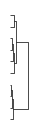

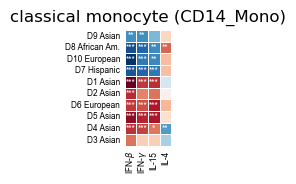

In [61]:
celltype_combo = 'classical monocyte (CD14_Mono)'
CYTOKINES = ["IFN-beta", "IFN-gamma", "IL-15", "IL-4"]

df_nes = all_results.loc[(all_results.celltype_combo == celltype_combo)].groupby(["donor_id", "cytokine"])["NES"].mean().to_frame().reset_index()
df_pivot = df_nes.pivot(
    index = "cytokine",
    columns = "donor_id",
    values = "NES"
).astype(float)
df_pivot = df_pivot.loc[CYTOKINES].T
df_annot = df_pivot.copy()


with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    df_annot[:] = ""
for donor_id in df_pivot.index:
    for cytokine in df_pivot.columns:
        qval = robust_results.loc[(robust_results.celltype_combo == celltype_combo) & (robust_results.cytokine == cytokine) & (robust_results.donor_id == donor_id)].qval_threshold
        if len(qval) != 0:
            qval = qval.values[0]
            if qval == 0.1:
                df_annot.loc[donor_id, cytokine] = "*"
            if qval == 0.05:
                df_annot.loc[donor_id, cytokine] = "**"
            if qval == 0.01:
                df_annot.loc[donor_id, cytokine] = "***"


linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='euclidean')
# linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='correlation')
dendro_col = sch.dendrogram(linkage_col, no_plot=True)
col_order = dendro_col['leaves']

fig, ax = plt.subplots(1, 1, figsize=(0.25, 1.5))
sch.dendrogram(linkage_col, ax=ax, color_threshold=0, no_labels=True, link_color_func=lambda _: "black", orientation="right")
ax.axis('off')
ax.collections[0].set_linewidth(0.5)
plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}_dendogram.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.show()


df_reordered = df_pivot.iloc[col_order]
annot_reordered = df_annot.iloc[col_order]

def get_ethnicity_label(x):
    assert len(x) == 1
    return x[0]

donor2label = {}
donor2label_ethnicity = dict(adata.obs.loc[adata.obs.donor_id.isin(df_pivot.index)].groupby("donor_id", observed=True)["self_reported_ethnicity"].unique().apply(get_ethnicity_label))
for donor in donor2label_ethnicity.keys():
    donor2label[donor] = f"D{donor_idcs[donor]}" + f" {format_ethnicity_str(donor2label_ethnicity[donor])}"
donor2label_ethnicity

fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
sns.heatmap(
    df_reordered,
    annot=annot_reordered,
    annot_kws = {"fontsize": 6, "family": "Arial"},
    fmt='s',
    cmap="RdBu_r",
    center=0,
    cbar=False,
    ax=ax,
    linewidths=0.5,
    linecolor='white',
    square=True,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis='both', which='both', length=0)

donor_labels = df_reordered.index
_donor_labels = [donor2label[d] for d in donor_labels]
ax.set_yticks(0.5 + np.arange(len(donor_labels)))
ax.set_yticklabels(_donor_labels, rotation=0, family="Arial", fontsize=6, va="center")

ax.set_xticks(0.5 + np.arange(df_reordered.shape[1]))
ax.set_xticklabels(format_cytokine_names(df_reordered.columns), family="Arial", fontsize=6)

plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.title(celltype_combo)
plt.show()

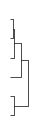

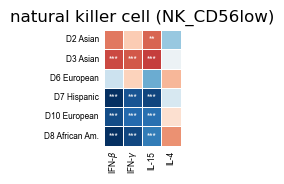

In [62]:
celltype_combo = 'natural killer cell (NK_CD56low)'
CYTOKINES = ["IFN-beta", "IFN-gamma", "IL-15", "IL-4"]

df_nes = all_results.loc[(all_results.celltype_combo == celltype_combo)].groupby(["donor_id", "cytokine"])["NES"].mean().to_frame().reset_index()
df_pivot = df_nes.pivot(
    index = "cytokine",
    columns = "donor_id",
    values = "NES"
).astype(float)
df_pivot = df_pivot.loc[CYTOKINES].T
df_annot = df_pivot.copy()


with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    df_annot[:] = ""
for donor_id in df_pivot.index:
    for cytokine in df_pivot.columns:
        qval = robust_results.loc[(robust_results.celltype_combo == celltype_combo) & (robust_results.cytokine == cytokine) & (robust_results.donor_id == donor_id)].qval_threshold
        if len(qval) != 0:
            qval = qval.values[0]
            if qval == 0.1:
                df_annot.loc[donor_id, cytokine] = "*"
            if qval == 0.05:
                df_annot.loc[donor_id, cytokine] = "**"
            if qval == 0.01:
                df_annot.loc[donor_id, cytokine] = "***"


linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='euclidean')
# linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='correlation')
dendro_col = sch.dendrogram(linkage_col, no_plot=True)
col_order = dendro_col['leaves']

fig, ax = plt.subplots(1, 1, figsize=(0.25, 1.5))
sch.dendrogram(linkage_col, ax=ax, color_threshold=0, no_labels=True, link_color_func=lambda _: "black", orientation="right")
ax.axis('off')
ax.collections[0].set_linewidth(0.5)
plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}_dendogram.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.show()


df_reordered = df_pivot.iloc[col_order]
annot_reordered = df_annot.iloc[col_order]

def get_ethnicity_label(x):
    assert len(x) == 1
    return x[0]

donor2label = {}
donor2label_ethnicity = dict(adata.obs.loc[adata.obs.donor_id.isin(df_pivot.index)].groupby("donor_id", observed=True)["self_reported_ethnicity"].unique().apply(get_ethnicity_label))
for donor in donor2label_ethnicity.keys():
    donor2label[donor] = f"D{donor_idcs[donor]}" + f" {format_ethnicity_str(donor2label_ethnicity[donor])}"
donor2label_ethnicity

fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
sns.heatmap(
    df_reordered,
    annot=annot_reordered,
    annot_kws = {"fontsize": 6, "family": "Arial"},
    fmt='s',
    cmap="RdBu_r",
    center=0,
    cbar=False,
    ax=ax,
    linewidths=0.5,
    linecolor='white',
    square=True,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis='both', which='both', length=0)

donor_labels = df_reordered.index
_donor_labels = [donor2label[d] for d in donor_labels]
ax.set_yticks(0.5 + np.arange(len(donor_labels)))
ax.set_yticklabels(_donor_labels, rotation=0, family="Arial", fontsize=6, va="center")

ax.set_xticks(0.5 + np.arange(df_reordered.shape[1]))
ax.set_xticklabels(format_cytokine_names(df_reordered.columns), family="Arial", fontsize=6)

plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.title(celltype_combo)
plt.show()

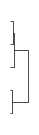

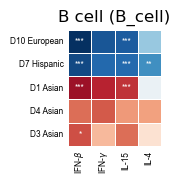

In [63]:
celltype_combo = 'B cell (B_cell)'
CYTOKINES = ["IFN-beta", "IFN-gamma", "IL-15", "IL-4"]

df_nes = all_results.loc[(all_results.celltype_combo == celltype_combo)].groupby(["donor_id", "cytokine"])["NES"].mean().to_frame().reset_index()
df_pivot = df_nes.pivot(
    index = "cytokine",
    columns = "donor_id",
    values = "NES"
).astype(float)
df_pivot = df_pivot.loc[CYTOKINES].T
df_annot = df_pivot.copy()


with warnings.catch_warnings():
    warnings.simplefilter(action='ignore', category=FutureWarning)
    df_annot[:] = ""
for donor_id in df_pivot.index:
    for cytokine in df_pivot.columns:
        qval = robust_results.loc[(robust_results.celltype_combo == celltype_combo) & (robust_results.cytokine == cytokine) & (robust_results.donor_id == donor_id)].qval_threshold
        if len(qval) != 0:
            qval = qval.values[0]
            if qval == 0.1:
                df_annot.loc[donor_id, cytokine] = "*"
            if qval == 0.05:
                df_annot.loc[donor_id, cytokine] = "**"
            if qval == 0.01:
                df_annot.loc[donor_id, cytokine] = "***"


linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='euclidean')
# linkage_col = sch.linkage(df_pivot.fillna(0), method='average', metric='correlation')
dendro_col = sch.dendrogram(linkage_col, no_plot=True)
col_order = dendro_col['leaves']

fig, ax = plt.subplots(1, 1, figsize=(0.25, 1.5))
sch.dendrogram(linkage_col, ax=ax, color_threshold=0, no_labels=True, link_color_func=lambda _: "black", orientation="right")
ax.axis('off')
ax.collections[0].set_linewidth(0.5)
plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}_dendogram.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.show()


df_reordered = df_pivot.iloc[col_order]
annot_reordered = df_annot.iloc[col_order]

def get_ethnicity_label(x):
    assert len(x) == 1
    return x[0]

donor2label = {}
donor2label_ethnicity = dict(adata.obs.loc[adata.obs.donor_id.isin(df_pivot.index)].groupby("donor_id", observed=True)["self_reported_ethnicity"].unique().apply(get_ethnicity_label))
for donor in donor2label_ethnicity.keys():
    donor2label[donor] = f"D{donor_idcs[donor]}" + f" {format_ethnicity_str(donor2label_ethnicity[donor])}"
donor2label_ethnicity

fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
sns.heatmap(
    df_reordered,
    annot=annot_reordered,
    annot_kws = {"fontsize": 6, "family": "Arial"},
    fmt='s',
    cmap="RdBu_r",
    center=0,
    cbar=False,
    ax=ax,
    linewidths=0.5,
    linecolor='white',
    square=True,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis='both', which='both', length=0)

donor_labels = df_reordered.index
_donor_labels = [donor2label[d] for d in donor_labels]
ax.set_yticks(0.5 + np.arange(len(donor_labels)))
ax.set_yticklabels(_donor_labels, rotation=0, family="Arial", fontsize=6, va="center")

ax.set_xticks(0.5 + np.arange(df_reordered.shape[1]))
ax.set_xticklabels(format_cytokine_names(df_reordered.columns), family="Arial", fontsize=6)

plt.savefig(
    os.path.join("./final_figures", f"enrichment_per_donor_{celltype_combo}.svg"),
    bbox_inches="tight",
    pad_inches=0,
    dpi=500,
    transparent=True,
)
plt.title(celltype_combo)
plt.show()